# Semana 8: Búsqueda de hiperparámetros

Título provisional: Generalización de políticas de aprendizaje por refuerzo ante diferentes niveles de fidelidad

Alumno: Brayan Bruce Pérez Escobar

Rama: `sprint5-busquedaHiperparametros`

## Resultados preliminares

ETenemos hasta ahora:

| Variante | η R3 | η R1 |
|---|---|---|
| Baseline (11 features) | 0.964 | 0.333 |
| Var1 · + margen | 0.967 | 0.000 |
| Var2 · − fase | 0.966 | 0.969 |

Hasta ahora PPO se entrenó con α = 3·10⁻⁴ y los demás valores por defecto de Stable-Baselines3, sin buscarlos, y solo en R3. El experimento principal entrena una política en cada nivel R1–R4, así que esta semana se busca una sola configuración de hiperparámetros que sirva para los cuatro niveles


In [5]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from nanoswarm.evaluation import ROOT, episode_seeds
from nanoswarm.utils.rollout import run_metadata

warnings.filterwarnings("ignore", message="IProgress not found")  # aviso de tqdm al importar Optuna
T_INICIO = time.time()
pd.set_option("display.precision", 3)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "figure.dpi": 110})
NIVEL_COLOR = {"R1": "#2a78d6", "R2": "#eb6834", "R3": "#1baf7a", "R4": "#eda100"}

# Cada resultado se guarda en disco para armar las tablas finales con datos reales
TABLAS = ROOT / "results" / "tables"
FIGURAS = ROOT / "results" / "figures"

print(json.dumps(run_metadata(), indent=2, ensure_ascii=False))

{
  "fecha": "2026-11-06T18:41:03",
  "git_commit": "008cd6e (con cambios sin commit)",
  "python": "3.12.7",
  "plataforma": "Windows-11-10.0.26300-SP0",
  "numpy": "2.5.3",
  "gymnasium": "1.4.0",
  "pandas": "3.0.6"
}


## 1. Método

Los valores están en `configs/train/search.yaml`, que es el archivo que lee la búsqueda.

### 1.1 Qué queda fijo

Lo que no se busca queda igual en todos los trials, para que la diferencia entre ellos se deba solo a los hiperparámetros:

| Elemento | Valor |
|---|---|
| Entorno | v0.2 (Var3), congelado |
| Observación | sin fase (9 features), Sprint 4 |
| Red | MLP 64 × 64 |
| Entornos en paralelo | 4 |
| gae_lambda / clip_range | 0.95 / 0.2 (estándar de PPO) |
| Semilla de entrenamiento | 0, la misma en todos los trials |

### 1.2 Espacio de búsqueda

Seis hiperparámetros de PPO. El control es la configuración usada en las semanas anteriores, que se compara contra la ganadora.

| Hiperparámetro | Qué controla | Rango | Control |
|---|---|---|---|
| `learning_rate` (α) | Tamaño de cada paso de aprendizaje | [1·10⁻⁴, 1·10⁻³], escala log | 3·10⁻⁴ |
| `n_steps` | Pasos por entorno antes de cada actualización | {256, 512, 1024} | 512 |
| `batch_size` | Tamaño de los minilotes | {64, 128, 256} | 256 |
| `n_epochs` | Veces que se reutiliza la misma experiencia | {5, 10, 20} | 10 |
| `gamma` (γ) | Cuánto pesa el futuro | {0.99, 0.995, 0.999} | 0.995 |
| `ent_coef` | Cuánto se premia explorar | [1·10⁻⁵, 1·10⁻²], escala log | 0 |

El espacio es una versión acotada del espacio de búsqueda de PPO de RL Baselines3 Zoo (Raffin, 2020) Los otros se dejan fijos para no pasar de los 6–8 hiperparámetros.

Por ahora se hace:

- **α** cubre la rejilla {1·10⁻⁴, 3·10⁻⁴, 1·10⁻³} , y es **constante**: un decaimiento dejaría al currículo con α pequeño justo al llegar a R4.
- **γ** importa por R1: sin flujo, una buena política necesita unos 630 pasos para entregar el enjambre, frente a unos 350 en R3. γ = 0.99 mira unos 100 pasos adelante y γ = 0.999 unos 1000.
- **ent_coef** del control es 0, fuera del rango buscado. No importa, porque el control se mide aparte.

### 1.3 Cómo se mide cada trial

Un trial es una configuración de hiperparámetros puesta a prueba. En cada uno:

1. Se entrena una política en cada nivel (R1, R2, R3 y R4), con 100 000 pasos por nivel. En el Sprint 3 la curva de aprendizaje en R3 llegó a su meseta cerca de ese punto (η ≈ 0.95), y después casi no cambió hasta los 300 000 pasos.
2. Cada 10 000 pasos se mide η de la política en su propio nivel, con 5 episodios de ajuste. Así sale una curva de 10 puntos por nivel.
3. Valor del trial = eficiencia muestral (promedio de η en esa curva), promediada en los cuatro niveles. También se guarda el η final de cada nivel.

Para decidir no se usa la transferencia a otros niveles, que es lo que mide la tesis, ni las semillas de reporte:

| Uso | Semillas |
|---|---|
| Evaluación durante la búsqueda | 5000–5004 (ajuste) |
| Reporte (no se usa en este sprint) | 9000–9029 |

### 1.4 Búsqueda y presupuesto

Se usa la aleatoria (RandomSampler de Optuna), pues tenemos 6 hiperparámetros y ninguna búsqueda anterior:



### 1.5 Regla de decisión

El control se mide igual que un trial (4 niveles, 100 000 pasos, mismas semillas), sin Optuna. La mejor configuración de la búsqueda lo reemplaza solo si su eficiencia muestral es al menos 0.02 mayor y su η final no queda más de 0.01 por debajo. Si no lo cumple, se mantiene la configuración actual. Se eligen además 2 configuraciones de respaldo.

### 1.6 Variables para las secciones siguientes


In [6]:
with open(ROOT / "configs" / "train" / "search.yaml", encoding="utf-8") as f:
    BUSQUEDA = yaml.safe_load(f)

ESPACIO = BUSQUEDA["espacio"]                  # rangos de los 6 hiperparámetros
CONTROL = BUSQUEDA["control"]                  # configuración de los Sprints 3 y 4
NIVELES = BUSQUEDA["objetivo"]["niveles"]      # R1–R4

DECISION = BUSQUEDA["decision"]               # regla de la sección 1.5
SEMILLAS_BUSQUEDA = episode_seeds("ajuste", BUSQUEDA["objetivo"]["episodios_evaluacion"])
assert not set(SEMILLAS_BUSQUEDA) & set(episode_seeds("reporte"))

print(f"Hiperparámetros: {', '.join(ESPACIO)}")
print(f"Niveles: {NIVELES}")
print(f"Semillas de evaluación: {SEMILLAS_BUSQUEDA[0]}–{SEMILLAS_BUSQUEDA[-1]}")
print(f"Trials por búsqueda: {BUSQUEDA['busqueda']['trials_por_busqueda']}")

Hiperparámetros: learning_rate, n_steps, batch_size, n_epochs, gamma, ent_coef
Niveles: ['R1', 'R2', 'R3', 'R4']
Semillas de evaluación: 5000–5004
Trials por búsqueda: 20


**Siguiente:** la sección 2 implementa un trial y lo prueba con un presupuesto corto antes de lanzar las búsquedas.

## 2. Código de la búsqueda y prueba corta

### 2.2 Prueba corta

se revisa es que todo el flujo funcione.

In [7]:
import shutil

from nanoswarm.hpo import SALIDA, buscar

shutil.rmtree(SALIDA / "prueba", ignore_errors=True)
t0 = time.time()
prueba = buscar("prueba", "random", n_trials=2, pasos_por_nivel=4_000, evaluar_cada=2_000, episodios=2, n_procesos=2)
print(f"Prueba: {time.time() - t0:.0f} s")
prueba[["trial_id", "estado", "evaluaciones", "pasos_por_nivel", *ESPACIO, "valor", "segundos"]]

Prueba: 91 s


,trial_id,estado,evaluaciones,pasos_por_nivel,learning_rate,n_steps,batch_size,n_epochs,gamma,ent_coef,valor,segundos
0,0,COMPLETE,2,4096,1.303e-04,256,128,20,0.995,1.481e-05,0.293,80.853
1,1,COMPLETE,2,4096,2.369e-04,256,64,5,0.995,4.335e-05,0.256,71.583


Cada fila es un trial: la configuración que propuso Optuna, cuántas evaluaciones alcanzó, su valor (eficiencia muestral promedio de los 4 niveles) y lo que tardó.

Verificaciones: que cada trial tenga los 4 niveles y todas sus evaluaciones, que los valores estén entre 0 y 1, que los hiperparámetros caigan dentro del espacio y que se hayan guardado los archivos:

In [8]:
def en_espacio(nombre, valor):
    p = ESPACIO[nombre]
    return valor in p["valores"] if p["tipo"] == "categorico" else p["min"] <= valor <= p["max"]


curvas = {t: pd.read_csv(SALIDA / "prueba" / f"trial_{t:03d}" / "curve.csv") for t in prueba["trial_id"]}
assert all(set(c["nivel"]) == set(NIVELES) and c["evaluacion"].max() == 2 for c in curvas.values())
assert prueba["valor"].between(0, 1).all()
assert all(en_espacio(n, v) for _, fila in prueba.iterrows() for n, v in fila[list(ESPACIO)].items())
assert (SALIDA / "prueba" / "journal.log").exists() and (SALIDA / "prueba" / "trials.csv").exists()
print("Verificaciones correctas. Curva del trial 0 (η por nivel en cada evaluación):")
curvas[0].pivot(index="nivel", columns="paso", values="eta")

Verificaciones correctas. Curva del trial 0 (η por nivel en cada evaluación):


paso,2048,4096
nivel,,
R1,0.000,0.000
R2,0.277,0.230
R3,0.330,0.335
R4,0.560,0.613


### 2.3 Costo de la búsqueda real


In [9]:
from nanoswarm.agents.ppo_sb3 import make_model
from nanoswarm.hpo import evaluar, ppo_config

metas = [json.loads((ROOT / "experiments" / "pilot" / f"sin_fase_R3_s{s}" / "meta.json").read_text()) for s in range(3)]
seg_por_paso = np.mean([m["train_seconds"] / m["config"]["timesteps"] for m in metas])

fijo, o, b = BUSQUEDA["fijo"], BUSQUEDA["objetivo"], BUSQUEDA["busqueda"]
seg_por_episodio = {}
for c in NIVELES:
    m = make_model(fijo["observacion"], c, 0, ppo_config(CONTROL, BUSQUEDA))
    t0 = time.time()
    evaluar(m, c, fijo["observacion"], fijo["entorno"], SEMILLAS_BUSQUEDA[:2])
    seg_por_episodio[c] = (time.time() - t0) / 2

evaluaciones = o["pasos_por_nivel"] // o["evaluar_cada"]
entrenar = len(NIVELES) * o["pasos_por_nivel"] * seg_por_paso
evaluar_s = evaluaciones * o["episodios_evaluacion"] * sum(seg_por_episodio.values())
rondas = -(-b["trials_por_busqueda"] // b["trials_en_paralelo"])  # trials en paralelo por tandas
pd.DataFrame([
    {"concepto": f"Entrenamiento por trial (4 × {o['pasos_por_nivel']:,} pasos)", "minutos": entrenar / 60},
    {"concepto": "Evaluaciones por trial (peor caso)", "minutos": evaluar_s / 60},
    {"concepto": "Trial completo", "minutos": (entrenar + evaluar_s) / 60},
    {"concepto": f"Búsqueda sin poda ({b['trials_por_busqueda']} trials, {rondas} tandas de {b['trials_en_paralelo']})",
     "minutos": rondas * (entrenar + evaluar_s) / 60},
]).set_index("concepto").round(0)

,minutos
concepto,
"Entrenamiento por trial (4 × 100,000 pasos)",24.0
Evaluaciones por trial (peor caso),4.0
Trial completo,28.0
"Búsqueda sin poda (20 trials, 3 tandas de 8)",84.0


.

## 3. Búsqueda aleatoria

### 3.1 Código de la búsqueda



In [ ]:
from nanoswarm.hpo import SALIDA, buscar

t0 = time.time()
aleatoria = buscar("random", "random")  # una fila por trial: hiperparámetros, estado, valor y métricas por nivel
aleatoria["minutos"] = aleatoria["segundos"] / 60
print(f"{len(aleatoria)} trials en {time.time() - t0:.0f} s")
print(aleatoria["estado"].value_counts().to_string())

### 3.2 Resultados de la corrida

La búsqueda se corrió por separado desde la terminal, con el mismo código (`python scripts/hpo.py --sampler random`). Se cargan los resultados de esa corrida, guardados en estos archivos:

| Archivo | Qué contiene |
|---|---|
| [experiments/hpo/random_salida.txt](../experiments/hpo/random_salida.txt) | Salida del comando: estado, evaluaciones, valor y segundos de cada trial, y el tiempo total |
| [experiments/hpo/random/journal.log](../experiments/hpo/random/journal.log) | Registro de Optuna: hiperparámetros, nota de cada evaluación intermedia, poda y horas de inicio y fin de cada trial |
| [experiments/hpo/random/trials.csv](../experiments/hpo/random/trials.csv) | Una fila por trial, con las métricas por nivel |
| [experiments/hpo/random/](../experiments/hpo/random/) `trial_XXX/` | Curva de aprendizaje (`curve.csv`) y configuración (`meta.json`) de cada trial |

La celda siguiente lee el `journal.log` para mostrar el inicio y el fin de la corrida, e imprime la salida del comando.

In [10]:
from nanoswarm.hpo import abrir_estudio


def registro(nombre, sampler):
    trials = abrir_estudio(nombre, sampler, BUSQUEDA).trials
    inicio = min(t.datetime_start for t in trials)
    fin = max(t.datetime_complete for t in trials if t.datetime_complete)
    print(f"{nombre}: {inicio:%Y-%m-%d %H:%M} → {fin:%H:%M} ({(fin - inicio).total_seconds() / 60:.0f} min)\n")
    print((SALIDA / f"{nombre}_salida.txt").read_text(encoding="utf-8"))


registro("random", "random")

random: 2026-11-06 15:03 → 16:41 (98 min)

 trial_id   estado  evaluaciones    valor    segundos
        0 COMPLETE            10 0.733050 2568.819065
        1 COMPLETE            10 0.811375 3003.340758
        2 COMPLETE            10 0.807075 3052.642922
        3   PRUNED            10 0.696575 3093.764683
        4 COMPLETE            10 0.773325 3000.419470
        5 COMPLETE            10 0.739425 2670.478504
        6 COMPLETE            10 0.766900 2481.326387
        7 COMPLETE            10 0.841775 3689.608673
        8   PRUNED             2 0.483750  553.625727
        9   PRUNED             2 0.417500  549.059278
       10   PRUNED             2 0.518875  445.696002
       11   PRUNED             4 0.640437 1005.528680
       12 COMPLETE            10 0.870125 1589.725747
       13   PRUNED             2 0.506250  582.170414
       14 COMPLETE            10 0.755100 2809.227764
       15   PRUNED             2 0.467500  438.861359
       16   PRUNED             2 0.4613

Cada fila de la tabla siguiente es un trial, ordenado por su valor. En los podados, el valor es el parcial de la evaluación en que se cortaron.

In [11]:
COLUMNAS = ["trial_id", "estado", "evaluaciones", *ESPACIO, "valor",
            *[f"eficiencia_{c}" for c in NIVELES], "eta_final", "minutos"]


def leer_busqueda(nombre):
    t = pd.read_csv(SALIDA / nombre / "trials.csv")
    t["minutos"] = t["segundos"] / 60
    return t


aleatoria = leer_busqueda("random")
print(aleatoria["estado"].value_counts().to_string())
print("Evaluaciones al podar:", aleatoria.query("estado == 'PRUNED'")["evaluaciones"].value_counts().to_dict())
aleatoria.sort_values("valor", ascending=False)[COLUMNAS]

estado
PRUNED      11
COMPLETE     9
Evaluaciones al podar: {2: 9, 10: 1, 4: 1}


,trial_id,estado,evaluaciones,learning_rate,n_steps,batch_size,n_epochs,gamma,ent_coef,valor,eficiencia_R1,eficiencia_R2,eficiencia_R3,eficiencia_R4,eta_final,minutos
12,12,COMPLETE,10,7.356e-04,512,256,5,0.995,4.912e-03,0.870,0.799,0.830,0.927,0.924,0.967,26.495
7,7,COMPLETE,10,2.000e-04,512,64,20,0.990,2.554e-03,0.842,0.684,0.852,0.915,0.915,0.950,61.493
1,1,COMPLETE,10,1.303e-04,256,128,20,0.995,1.481e-05,0.811,0.600,0.936,0.782,0.928,0.970,50.056
2,2,COMPLETE,10,6.837e-04,512,128,20,0.990,2.190e-05,0.807,0.507,0.887,0.912,0.922,0.853,50.877
4,4,COMPLETE,10,6.079e-04,1024,128,10,0.990,1.726e-03,0.773,0.478,0.895,0.809,0.911,0.949,50.007
6,6,COMPLETE,10,1.041e-04,256,256,10,0.999,1.570e-03,0.767,0.499,0.884,0.759,0.926,0.712,41.355
14,14,COMPLETE,10,1.652e-04,256,64,20,0.999,2.796e-05,0.755,0.300,0.903,0.874,0.944,0.710,46.820
5,5,COMPLETE,10,1.299e-04,256,128,10,0.990,7.967e-05,0.739,0.340,0.832,0.881,0.905,0.863,44.508
0,0,COMPLETE,10,2.369e-04,256,64,5,0.995,4.335e-05,0.733,0.300,0.921,0.793,0.918,0.718,42.814
3,3,PRUNED,10,9.750e-04,256,128,20,0.999,2.577e-04,0.697,NaN,NaN,NaN,NaN,NaN,51.563


- **9 trials completos y 11 podados.** Nueve se podaron en la segunda evaluación (20 000 pasos), uno en la cuarta y otro (el 3) recién en la última. Los podados en la segunda evaluación duraron 5 a 10 minutos en vez de 40 a 60, y de ahí viene el ahorro de tiempo.
- **La mejor configuración es el trial 12** (valor 0.870): α = 7·10⁻⁴, `n_steps` 512, `batch_size` 256, 5 épocas, γ = 0.995 y `ent_coef` ≈ 5·10⁻³. Comparte `n_steps`, `batch_size` y γ con el control, y cambia en una α más alta, menos épocas y algo de exploración.
- **R1 es lo que separa a las configuraciones.** Entre los completos, la eficiencia en R1 va de 0.30 a 0.80, mientras que en R2, R3 y R4 queda entre 0.76 y 0.94. Sin flujo, el enjambre solo avanza con la fuerza de control y los episodios son largos (unos 630 pasos frente a unos 350 en R3), así que la política tarda más en aprender. El trial 12 gana porque es el que aprende más rápido en R1 (0.80).

**¿La poda cortó configuraciones que podían ser buenas?** Se comparan las notas parciales en la segunda evaluación, que es donde se podó a la mayoría:

In [12]:
parciales = pd.DataFrame([{"trial_id": t.number, "estado": t.state.name,
                           "nota en evaluación 2": t.intermediate_values.get(2), "nota final": t.value}
                          for t in abrir_estudio("random", "random", BUSQUEDA).trials])
parciales.sort_values("nota en evaluación 2")

,trial_id,estado,nota en evaluación 2,nota final
19,19,PRUNED,0.385,0.385
18,18,PRUNED,0.387,0.387
9,9,PRUNED,0.418,0.418
5,5,COMPLETE,0.422,0.739
16,16,PRUNED,0.461,0.461
15,15,PRUNED,0.468,0.468
4,4,COMPLETE,0.470,0.773
8,8,PRUNED,0.484,0.484
13,13,PRUNED,0.506,0.506
17,17,PRUNED,0.509,0.509


En la segunda evaluación las notas de los trials que se podaron (0.39 a 0.52) se superponen con las de trials que terminaron bien: el 5 tenía 0.42 y terminó en 0.74, y el 4 tenía 0.47 y terminó en 0.77. Esos dos no se podaron solo porque estaban entre los 5 primeros, que Optuna no poda. Es decir, a los 20 000 pasos todavía no se distingue una configuración mala de una que arranca lento, y algunos de los trials podados podrían haber sido competitivos. Se registra como limitación (sección 6).

**Siguiente:** la sección 4 compara los trials con la configuración actual.

## 4. Comparación con el control: gráfico de evolución y tabla top-k

### 4.1 Control y registro de todos los trials

El control (configuración de los Sprints 3 y 4) se midió como un trial más con `python scripts/hpo.py --control`. Todos los trials se guardan en `logs/hpo_runs.csv`, con las columnas que pide la clase: id, parámetros, semilla, partición, métrica (media y desviación entre niveles), estado y tiempo.

In [13]:
control = json.loads((SALIDA / "control" / "resumen.json").read_text())
todos = aleatoria.copy()
todos["particion"] = f"ajuste {SEMILLAS_BUSQUEDA[0]}–{SEMILLAS_BUSQUEDA[-1]}"
hpo_runs = todos.rename(columns={"valor": "metric_mean", "eficiencia_std": "metric_std"})[
    ["busqueda", "trial_id", "estado", *ESPACIO, "semilla", "particion", "metric_mean", "metric_std", "eta_final",
     *[f"eficiencia_{c}" for c in NIVELES], "evaluaciones", "pasos_por_nivel", "segundos"]]
hpo_runs.to_csv(ROOT / "logs" / "hpo_runs.csv", index=False)
print(f"Guardado: logs/hpo_runs.csv ({len(hpo_runs)} trials)")
pd.DataFrame([{"configuración": "control", "valor": control["eficiencia"], "eta_final": control["eta_final"],
               **{f"eficiencia_{c}": control[f"eficiencia_{c}"] for c in NIVELES},
               "minutos": control["segundos"] / 60}]).set_index("configuración")

Guardado: logs/hpo_runs.csv (20 trials)


,valor,eta_final,eficiencia_R1,eficiencia_R2,eficiencia_R3,eficiencia_R4,minutos
configuración,,,,,,,
control,0.875,0.961,0.8,0.832,0.936,0.931,47.762


### 4.2 Gráfico de evolución

Considerando la poda, relleno si terminó, vacío si se podó (su valor es el parcial al podarlo). La línea es el mejor valor encontrado hasta ese trial y la línea punteada es el control.

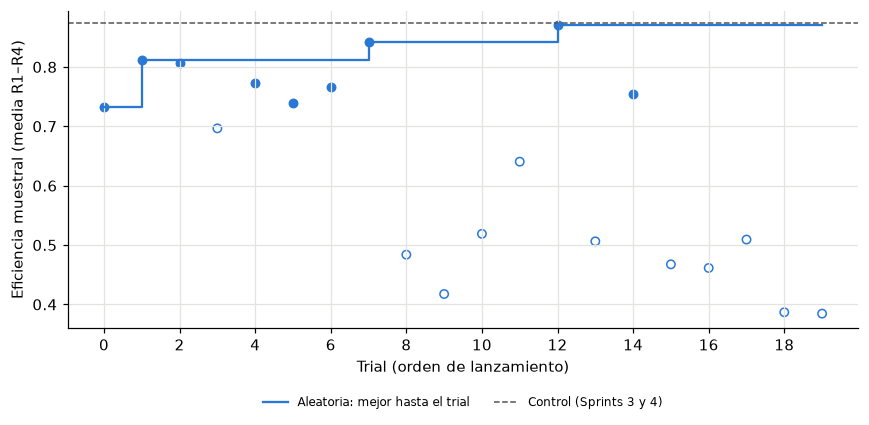

In [14]:
COLOR_BUSQUEDA = {"random": "#2a78d6"}
ETIQUETA = {"random": "Aleatoria"}
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, t in todos.groupby("busqueda"):
    t = t.sort_values("trial_id")
    c = COLOR_BUSQUEDA[nombre]
    completos = t["estado"] == "COMPLETE"
    ax.scatter(t.loc[completos, "trial_id"], t.loc[completos, "valor"], color=c, s=30)
    ax.scatter(t.loc[~completos, "trial_id"], t.loc[~completos, "valor"], facecolors="none", edgecolors=c, s=30)
    mejor = t["valor"].where(completos).cummax().ffill()
    ax.step(t["trial_id"], mejor, where="post", color=c, label=f"{ETIQUETA[nombre]}: mejor hasta el trial")
ax.axhline(control["eficiencia"], color="#555555", ls="--", lw=1, label="Control (Sprints 3 y 4)")
ax.set_xlabel("Trial (orden de lanzamiento)")
ax.set_ylabel("Eficiencia muestral (media R1–R4)")
ax.set_xticks(range(0, BUSQUEDA["busqueda"]["trials_por_busqueda"], 2))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIGURAS / "fig10_sprint5_evolucion.png", bbox_inches="tight")
plt.show()

La mejor configuración se encontró en el trial 12 (0.870). Ningún trial superó al control (0.875, línea punteada): el mejor quedó 0.005 por debajo, una diferencia dentro del ruido de evaluar con 5 episodios. Los trials del 8 en adelante se podaron casi todos en la segunda evaluación, por eso aparecen vacíos y abajo.

### 4.3 Tabla top-k


In [15]:
TOP_K = 5
top = todos.query("estado == 'COMPLETE'").nlargest(TOP_K, "valor").copy()
top["parámetros"] = top.apply(lambda r: f"α={r.learning_rate:.1e}, n_steps={r.n_steps}, batch={r.batch_size}, "
                                         f"épocas={r.n_epochs}, γ={r.gamma}, ent={r.ent_coef:.1e}", axis=1)
top["eficiencia (media ± desv.)"] = top.apply(lambda r: f"{r.valor:.3f} ± {r.eficiencia_std:.3f}", axis=1)
top["búsqueda"] = top["busqueda"].map(ETIQUETA)
tabla_top = top[["búsqueda", "trial_id", "parámetros", "eficiencia (media ± desv.)", "eficiencia_R1", "eta_final", "minutos"]]
tabla_top.to_csv(TABLAS / "sprint5_top_k.csv", index=False)
tabla_top

,búsqueda,trial_id,parámetros,eficiencia (media ± desv.),eficiencia_R1,eta_final,minutos
12,Aleatoria,12,"α=7.4e-04, n_steps=512, batch=256, épocas=5, γ...",0.870 ± 0.065,0.799,0.967,26.495
7,Aleatoria,7,"α=2.0e-04, n_steps=512, batch=64, épocas=20, γ...",0.842 ± 0.109,0.684,0.950,61.493
1,Aleatoria,1,"α=1.3e-04, n_steps=256, batch=128, épocas=20, ...",0.811 ± 0.158,0.600,0.970,50.056
2,Aleatoria,2,"α=6.8e-04, n_steps=512, batch=128, épocas=20, ...",0.807 ± 0.201,0.507,0.853,50.877
4,Aleatoria,4,"α=6.1e-04, n_steps=1024, batch=128, épocas=10,...",0.773 ± 0.202,0.478,0.949,50.007


Las mejores configuraciones no comparten un mismo valor de cada hiperparámetro: el trial 12 usa 5 épocas y α = 7·10⁻⁴, y el 7 usa 20 épocas y α = 2·10⁻⁴. Lo que sí comparten es la eficiencia en R1, la más alta de todos los trials (0.80 y 0.68). La desviación entre niveles (columna media ± desv.) sale casi toda de R1, que es el nivel más difícil.

## 5. Importancia de los hiperparámetros

### 5.1 Importancia (PED-ANOVA): Se calcula con los trials completos, tomando como "mejores" el 25 % superior.

Trials completos usados: 9


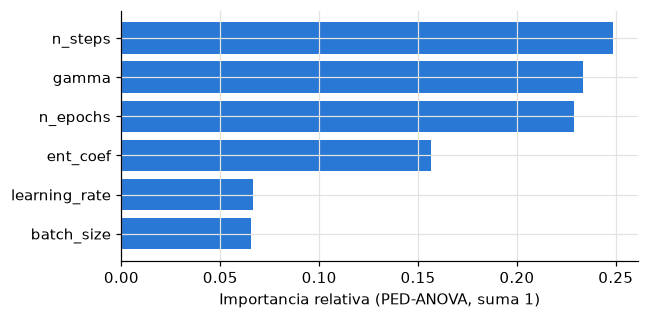

In [16]:
import optuna

from nanoswarm.hpo import abrir_estudio

conjunto = optuna.create_study(direction="maximize")
for nombre in ["random"]:
    conjunto.add_trials([t for t in abrir_estudio(nombre, nombre, BUSQUEDA).trials if t.state.name == "COMPLETE"])
importancia = optuna.importance.get_param_importances(
    conjunto, evaluator=optuna.importance.PedAnovaImportanceEvaluator(target_quantile=0.25))
importancia = pd.Series(importancia, name="importancia").sort_values()
print(f"Trials completos usados: {len(conjunto.trials)}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(importancia.index, importancia.values, color="#2a78d6")
ax.set_xlabel("Importancia relativa (PED-ANOVA, suma 1)")
fig.tight_layout()
fig.savefig(FIGURAS / "fig11_sprint5_importancia.png", bbox_inches="tight")
plt.show()

Con solo 9 trials completos la importancia es inestable: al cambiar el porcentaje de trials que se toma como "mejores" (25 % frente a 10 %) el orden cambia por completo, así que no se puede afirmar cuál hiperparámetro importa más. Difícil tomar esto para decidir

### 5.2 Valor de cada trial frente a cada hiperparámetro

Cada panel muestra la eficiencia de los trials completos según el valor que tomó un hiperparámetro; la línea punteada es el valor del control. Sirve para ver en qué dirección conviene moverlo y si las mejores configuraciones quedaron dentro del rango o pegadas a un bord

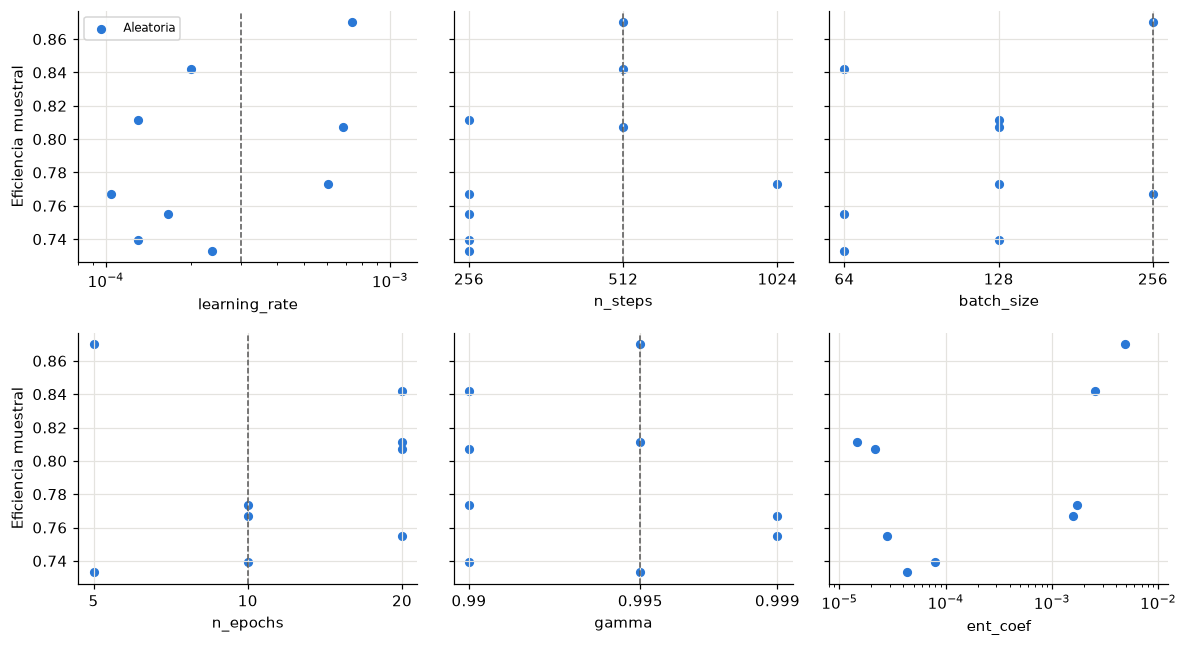

In [17]:
completos = todos.query("estado == 'COMPLETE'")
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for ax, nombre in zip(axes.flat, ESPACIO):
    for b, t in completos.groupby("busqueda"):
        ax.scatter(t[nombre], t["valor"], color=COLOR_BUSQUEDA[b], s=25, label=ETIQUETA[b])
    if CONTROL[nombre] > 0:  # ent_coef = 0 del control no cabe en escala log
        ax.axvline(CONTROL[nombre], color="#555555", ls="--", lw=1)
    p = ESPACIO[nombre]
    if p["tipo"] == "categorico":
        if nombre != "gamma":
            ax.set_xscale("log", base=2)
        ax.set_xticks(p["valores"], [str(v) for v in p["valores"]])
        ax.minorticks_off()
    else:
        ax.set_xscale("log")
        ax.set_xlim(p["min"] * 0.8, p["max"] * 1.25)
    ax.set_xlabel(nombre)
for ax in axes[:, 0]:
    ax.set_ylabel("Eficiencia muestral")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "fig12_sprint5_slice.png", bbox_inches="tight")
plt.show()

- **α :** las configuraciones buenas aparecen con α bajo (2·10⁻⁴) y alto (7·10⁻⁴), y el control usa 3·10⁻⁴. Dentro del rango buscado no hay una tendencia clara.
- **γ:** los dos trials con γ = 0.999 quedaron entre los más bajos; los mejores usan 0.99 o 0.995.
- **ent_coef:** los dos mejores trials tienen los valores más altos que se probaron (2.6·10⁻³ y 4.9·10⁻³), pero el control, sin exploración, rinde igual. Es una tendencia débil.
- **Bordes:** ningún hiperparámetro tiene a las mejores configuraciones pegadas a un borde del rango, así que los rangos fueron adecuados.



## 6. Decisión y conclusiones

### 6.1 Configuración ganadora


In [18]:
mejor = completos.nlargest(1 + DECISION["respaldos"], "valor")
ganadora, respaldos = mejor.iloc[0], mejor.iloc[1:]
mejora = ganadora["valor"] - control["eficiencia"]
caida = control["eta_final"] - ganadora["eta_final"]
cumple = mejora >= DECISION["mejora_minima"] and caida <= DECISION["caida_max_eta_final"]
decision = pd.DataFrame([
    {"criterio": "Mejora en eficiencia muestral frente al control", "valor": f"{mejora:+.3f}",
     "umbral": f"≥ {DECISION['mejora_minima']}", "cumple": mejora >= DECISION["mejora_minima"]},
    {"criterio": "Caída del η final frente al control", "valor": f"{caida:+.3f}",
     "umbral": f"≤ {DECISION['caida_max_eta_final']}", "cumple": caida <= DECISION["caida_max_eta_final"]},
]).set_index("criterio")
print(f"Mejor de la búsqueda: trial {ganadora['trial_id']} ({ganadora['valor']:.3f}); control: {control['eficiencia']:.3f}. "
      f"{'Reemplaza al control.' if cumple else 'No cumple la regla: se mantiene el control.'}")
decision

Mejor de la búsqueda: trial 12 (0.870); control: 0.875. No cumple la regla: se mantiene el control.


,valor,umbral,cumple
criterio,,,
Mejora en eficiencia muestral frente al control,-0.005,≥ 0.02,False
Caída del η final frente al control,-0.006,≤ 0.01,True


In [19]:
# Si la mejor no cumple la regla, la elegida es el control y los respaldos son las mejores de la búsqueda
roles = ["elegida"] + ["respaldo"] * DECISION["respaldos"] if cumple else ["respaldo"] * DECISION["respaldos"]
de_busqueda = mejor.head(len(roles)).assign(rol=[f"{r} (trial {t})" for r, t in zip(roles, mejor["trial_id"])])
final = pd.concat([
    pd.DataFrame([{"rol": "control (Sprints 3 y 4)" + ("" if cumple else ", elegida"), **CONTROL,
                   "eficiencia": control["eficiencia"], "eta_final": control["eta_final"]}]),
    de_busqueda[["rol", *ESPACIO, "valor", "eta_final"]].rename(columns={"valor": "eficiencia"}),
], ignore_index=True).set_index("rol")
final.to_csv(TABLAS / "sprint5_decision.csv")
final

,learning_rate,n_steps,batch_size,n_epochs,gamma,ent_coef,eficiencia,eta_final
rol,,,,,,,,
"control (Sprints 3 y 4), elegida",3.000e-04,512,256,10,0.995,0.000,0.875,0.961
respaldo (trial 12),7.356e-04,512,256,5,0.995,0.005,0.870,0.967
respaldo (trial 7),2.000e-04,512,64,20,0.990,0.003,0.842,0.950


Por lo tanto, se mantiene la configuración actual en α = 3·10⁻⁴, n_steps en 512, batch_size en 256, 10 épocas y γ = 0.995. Pues la mejor configuración de la búsqueda (trial 12) no la supera en 0.02

In [20]:
ruta = ROOT / "logs" / "metrics_sprint5_hpo.txt"
with open(ruta, "w", encoding="utf-8") as f:
    f.write("# Métricas: sprint5_hpo\n\n")
    f.write("## Metadatos\n" + json.dumps(run_metadata(), indent=2, ensure_ascii=False) + "\n\n")
    f.write("## Configuración (configs/train/search.yaml)\n" + json.dumps(BUSQUEDA, indent=2, ensure_ascii=False) + "\n\n")
    f.write("## Trials por búsqueda\n" + todos.groupby(["busqueda", "estado"]).size().to_string() + "\n\n")
    f.write("## Control\n" + json.dumps(control, indent=2) + "\n\n")
    f.write("## Top-k\n" + tabla_top.to_string(index=False) + "\n\n")
    f.write("## Importancia (PED-ANOVA)\n" + importancia.sort_values(ascending=False).round(3).to_string() + "\n\n")
    f.write("## Decisión\n" + decision.to_string() + "\n\n" + final.to_string() + "\n\n")
    f.write(f"Tiempo del notebook: {(time.time() - T_INICIO) / 60:.1f} min\n")
print(f"Guardado: {ruta.relative_to(ROOT)}")

Guardado: logs\metrics_sprint5_hpo.txt


### 6.2 Conclusiones

La configuración usada en las semanas anteriores era adecuada pues en una búsqueda de 20 configuraciones en los cuatro niveles, ninguna la superó. Por lo que α = 3·10⁻⁴ queda justificada con datos de los cuatro niveles.

Ademas se nota que R1 es el nivel que separa a las configuraciones, PPO tarda mucho más en aprender con eficiencia de 0.30 a 0.80 frente a 0.76–0.94 en los otros niveles. A revisar.

La poda es un método que nos ahorró tiempo para una primera revisión, 11 de 20 trials se cortaron, la mayoría a los 5–10 minutos. Pero esto nos da limitaciones como:

- La poda actuó desde la segunda evaluación (20 000 pasos). En ese punto las notas de configuraciones buenas y malas se superponen (sección 3), así que algunos trials podados podrían haber sido competitivos.

- Cada trial usó una sola semilla de entrenamiento y 5 episodios por evaluación, así que diferencias menores a ~0.02 son ruido.


### 6.4 Trabajo pendiente

- Se requiere confirmar las mejores configuraciones y el control con 3 semillas de entrenamiento y más episodios de evaluación. y hacer una poda mas alta que 2.
- Es mejor repetir la búsqueda con el método bayesiano (TPE) y comparar con la aleatoria.
- Revisar entre contextos, usar curvas por nivel para ver si R2 y R3 se aprenden distinto.